# Aquifer influx and CRM

Most reservoirs sit on an aquifer. As you produce, water encroaches and supports
pressure. van Everdingen and Hurst described that influx; Klins and Marsal–Walsh
approximations make it a function you can fit.

This notebook reproduces the PetroWiki history-match example, then shows how to
turn the influx (or a field imbalance) into a **pseudo-injector** so CRM can
attribute aquifer support instead of inventing injector–producer gains.


In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pywaterflood.aquifer import aquifer_production, effective_reservoir_radius
from scipy.optimize import curve_fit


## PetroWiki worked example

Pore volume 385 MMrb, $\phi=31\%$, $h=20$ ft, semicircle (180°). Pressure and
measured cumulative influx vs time:


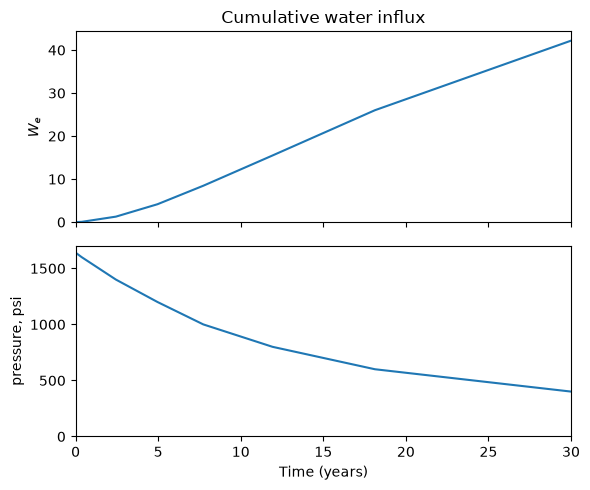

In [2]:
influx = pd.DataFrame(
    {
        "j": range(1, 9),
        "time": [0, 0.368, 2.439, 4.957, 7.732, 11.926, 18.126, 30.044],
        "pressure": [1640.0, 1600, 1400, 1200, 1000, 800, 600, 400],
        "cum_water_influx": [0.0, 0.062, 1.272, 4.156, 8.455, 15.494, 26.014, 42.243],
    }
)
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(6, 5))
influx.plot(x="time", y="cum_water_influx", ax=ax1, legend=False)
influx.plot(x="time", y="pressure", ax=ax2, legend=False)
ax1.set(xlim=(0, 30), ylim=(0, None), ylabel=r"$W_e$", title="Cumulative water influx")
ax2.set(ylim=(0, None), ylabel="pressure, psi", xlabel="Time (years)")
fig.tight_layout()


Effective reservoir radius $r_o$ from pore volume, porosity, thickness, and the
open angle of the aquifer:


In [3]:
phi = 0.31
V_pr = 385  # MMrb in the example scaling
r_reservoir = effective_reservoir_radius(V_pr, phi, 20, 180)
print(f"r_o = {r_reservoir:.2f} ft")


r_o = 14.90 ft


Dimensionless time and the aquifer constant:

$$
t_D = k_t t, \qquad
k_t = \frac{2.309 k_a}{\phi_a \mu_w c_t r_o^2}, \qquad
U = 1.119\, r_o^2 \phi c_t
$$


In [4]:
k_a = 64.2
mu = 0.48
c_t = 5.88
phi_a = 0.27
k_t = 2.309 * k_a / (phi_a * mu * c_t * r_reservoir**2)
aquifer_constant = 1.119 * 8.7 * r_reservoir**2 * phi * c_t / 1e6
influx = influx.assign(t_D=lambda x: k_t * x.time)
print(f"k_t = {k_t:.4g}  U = {aquifer_constant:.4g}")


k_t = 0.8764  U = 0.003939


`aquifer_production` takes the stepwise pressure drop, $t_D$, the radius ratio
$r_{eD}$, and $U$. `method="klins"` is the default finite-aquifer approximation.


,time,pressure,t_D,cum_water_influx,W_e
0,0.000,1640.0,0.000000,0.000,0.000000
1,0.368,1600.0,0.322520,0.062,0.067264
2,2.439,1400.0,2.137571,1.272,1.347048
3,4.957,1200.0,4.344378,4.156,4.386056
4,7.732,1000.0,6.776423,8.455,8.858923
5,11.926,800.0,10.452098,15.494,16.269779
6,18.126,600.0,15.885856,26.014,26.788354
7,30.044,400.0,26.330942,42.243,42.438753


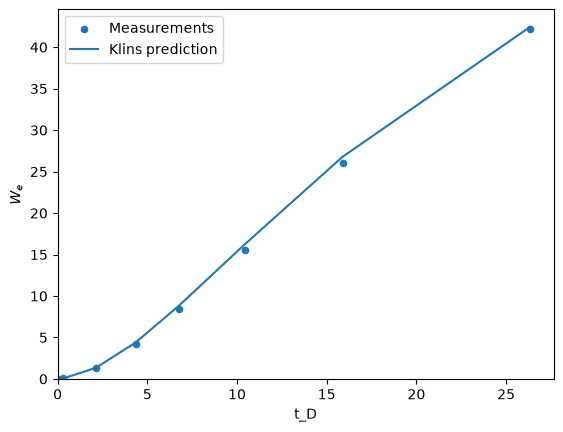

In [5]:
influx = influx.assign(
    pressure_ave=lambda x: x.pressure.rolling(2, min_periods=1).mean(),
    pressure_delta=lambda x: (-x.pressure_ave.diff(1)).fillna(0),
)
r_ed = 5
w_ek = aquifer_production(
    influx["pressure_delta"].to_numpy(),
    influx["t_D"].to_numpy(),
    r_ed=r_ed,
    method="klins",
    aquifer_constant=aquifer_constant,
)
influx["W_e"] = w_ek

ax = plt.axes()
influx.plot(x="t_D", y="cum_water_influx", kind="scatter", label="Measurements", ax=ax)
influx.plot("t_D", "W_e", label="Klins prediction", ax=ax)
ax.set(xlim=(0, None), ylim=(0, None), ylabel=r"$W_e$")
ax.legend()
influx[["time", "pressure", "t_D", "cum_water_influx", "W_e"]]


Fit $r_{eD}$ and $U$ when they are unknown:


r_ed = 5.12, U = 0.00383


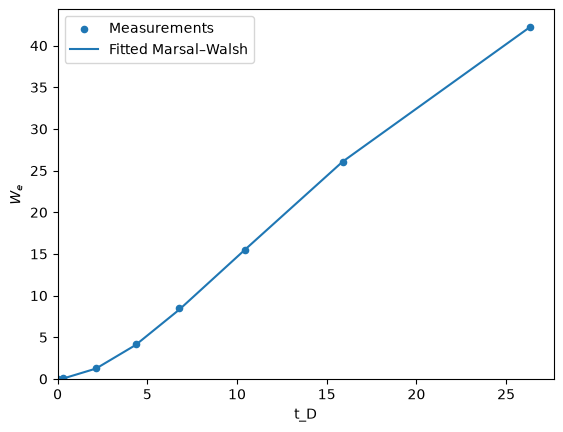

In [6]:
(r_ed_fit, u_fit), _ = curve_fit(
    lambda t_d, r, u: aquifer_production(
        influx["pressure_delta"].to_numpy(), t_d, r, "marsal-walsh", u
    ),
    xdata=influx["t_D"].to_numpy(),
    ydata=influx["cum_water_influx"].to_numpy(),
    p0=[1.2, 1e-3],
    bounds=[(1.01, 0), (np.inf, np.inf)],
)
w_fit = aquifer_production(
    influx["pressure_delta"].to_numpy(),
    influx["t_D"].to_numpy(),
    r_ed_fit,
    "marsal-walsh",
    u_fit,
)
ax = plt.axes()
influx.plot(x="t_D", y="cum_water_influx", kind="scatter", label="Measurements", ax=ax)
ax.plot(influx["t_D"], w_fit, label="Fitted Marsal–Walsh")
ax.legend()
ax.set(xlim=(0, None), ylim=(0, None), ylabel=r"$W_e$")
print(f"r_ed = {r_ed_fit:.2f}, U = {u_fit:.3g}")


## Feed influx into CRM

CRM only sees injectors you give it. If field production runs above field
injection, the missing support is often the aquifer. Two practical columns:

1. **Imbalance pseudo-injector** — `max(field production − field injection, 0)`
   each month. No aquifer model required. Fast, crude.
2. **$W_e$ rate** — difference of cumulative influx, aligned to the CRM time
   grid. Uses the physics above.

Append that column to `injection`, give it an ID like `"AQUIFER"`, and fit CRM
with `constraints="up-to one"`. Gains in the aquifer column are the producers
that actually receive aquifer support.

```python
field_q = production.sum(axis=1)
field_i = injection.sum(axis=1)
q_aq = np.clip(field_q - field_i, 0.0, None)           # option 1
# q_aq = np.diff(np.concatenate([[0.0], W_e]), axis=0)  # option 2

injection_ext = np.column_stack([injection, q_aq])
injector_ids = [*original_injector_ids, "AQUIFER"]

crm.fit(production, injection_ext, time, constraints="up-to one", ...)
print(crm.gains[:, -1])  # aquifer support by producer
```

Keep the original injectors. Do not replace them with the imbalance — you want
both the flood and the aquifer in the same $f_{ij}$ table.


positive influx steps: 7 of 8


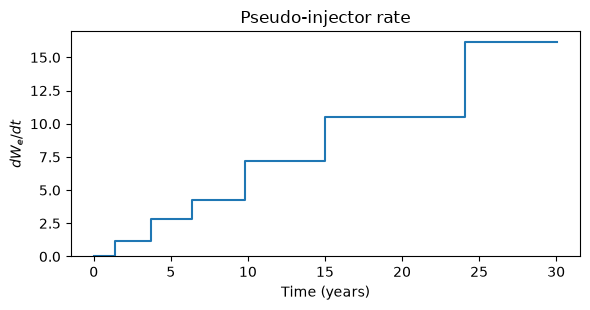

In [7]:
# Sketch on this example: influx rate from fitted W_e
w_e_rate = np.diff(np.concatenate([[0.0], w_fit]))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.step(influx["time"], w_e_rate, where="mid")
ax.set(xlabel="Time (years)", ylabel=r"$dW_e/dt$", ylim=(0, None), title="Pseudo-injector rate")
fig.tight_layout()
print("positive influx steps:", int((w_e_rate > 0).sum()), "of", len(w_e_rate))


## When to reach for this notebook

- Field production stays above injection after fill-up
- CRM with `"up-to one"` still under-predicts several producers
- You have a pressure history (even coarse) to build $t_D$

If the imbalance is small and noisy, skip the aquifer model and let `"up-to one"`
leave unused injection. Forcing `"sum-to-one"` on a field with aquifer support
will dump that extra production onto the nearest injectors.
